In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import os



# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)

    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(Q, nbins=30, unfolded_cutoff=0.1, wopt=None):
    k = 0.008314
    T = 298.0
    kT = k * T

    
    if wopt is None:
        wopt = np.ones(Q.shape[0])/Q.shape[0]
        

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q)
    centers_post, fel_post = compute_FEL(Q, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q > native_cutoff)[0]

    dG_prior = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q > native_cutoff2)[0]
    unfolded = np.where(Q < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]


proteins = ['ACBP']
protein = proteins[0]
ensemble_master_dir = 'BIOEMU_DATA'
outdir = './plots_ACBP/'

Posterior 1: phi = 0.8860, chi2 = 32.2418
Posterior 2: phi = 0.5674, chi2 = 10.3758


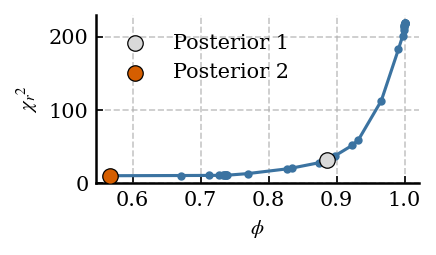

In [2]:
# chi2 vs phi from the NMR ensemble

protein = proteins[0]

# reweighting data NMR
wopt_array = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]
chi2 = rewdata[0,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
# posterior 2 = final with phi > 0.1
wopt2 = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify the three posterior points
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1: phi = {phi[idx_post1]:.4f}, chi2 = {chi2[idx_post1]:.4f}")
print(f"Posterior 2: phi = {phi[idx_post2]:.4f}, chi2 = {chi2[idx_post2]:.4f}")

# colours
COLOR_CURVE = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"

# sort by phi for a clean line
order = np.argsort(phi)

fig, ax = plt.subplots(figsize=(3, 1.8))

ax.plot(phi[order], chi2[order], "-o", color=COLOR_CURVE, markersize=3, linewidth=1.5, zorder=2)

# highlight selected posteriors
ax.scatter(phi[idx_post1], chi2[idx_post1], s=55, color=COLOR_POST1, edgecolor="black", linewidth=0.6, label="Posterior 1", zorder=4)
ax.scatter(phi[idx_post2], chi2[idx_post2], s=55, color=COLOR_POST2, edgecolor="black", linewidth=0.6, label="Posterior 2", zorder=4)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\chi$$_{r}$$^{2}$")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig(outdir+"chi2_vs_phi_NMR.pdf") 
plt.show()

Posterior 1 phi = 0.8860
Posterior 2 phi = 0.5674


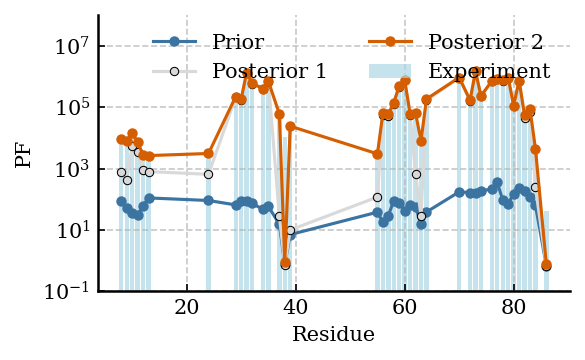

In [3]:
# comparison of NMR protection factors and prior/posterior

protein = proteins[0]

exp = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{protein}.csv')

# get fopen
fopen = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/O.npy')
res = np.loadtxt(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# posterior 2 = final
wopt2 = np.load(f'../../BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi values
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1 phi = {phi[idx_post1]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF1_plot = PF1[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, ax = plt.subplots(figsize=(4,2.5))

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", alpha=0.7, label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF1_plot, "-o", color=COLOR_POST1, markeredgecolor="black", markeredgewidth=0.5, markersize=4, linewidth=1.5, label=rf"Posterior 1", zorder=4)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label=rf"Posterior 2", zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1, 1e8)
ax.legend(frameon=False, ncol=2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig(outdir+'EXP_vs_CALC_PF_NMR.pdf')
plt.show()

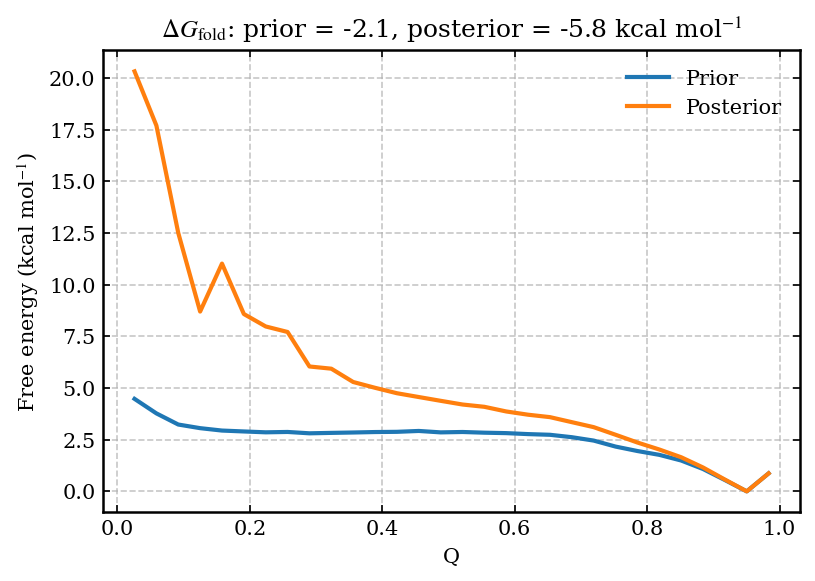

In [6]:
# free energy landscape of folding as a function of Q


nbins = 30

k = 0.008314
T = 298.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
unfolded_cutoff = 0.35

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    if traj == trajs[0]:
        Q = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        Q = Q[okframes]
    else:
        tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        Q = np.concatenate((Q, tmpQ[okframes]), axis=0)

w_prior = np.ones(len(Q))/len(Q)
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate folding free energies
folded = np.where(Q > unfolded_cutoff)[0]
unfolded = np.where(Q < unfolded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use the same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(Q, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('Q')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

-5.4
0.5
-1.8780952890702545
-4.494918150019878
-4.811806054921246


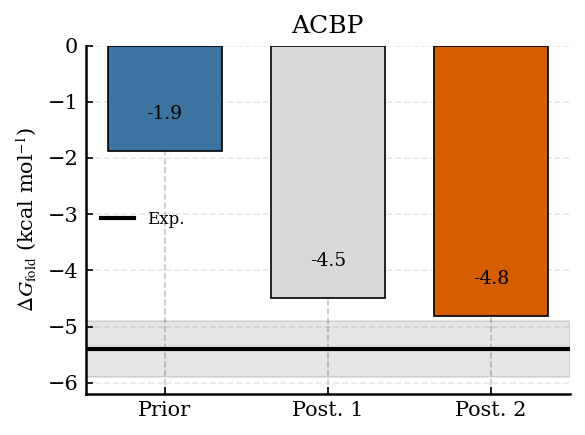

In [7]:
# barplot comparing experimental, prior, posterior 1, and posterior 2 folding free energies

protein = proteins[0]

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

# experimental dG
exp_dG, exp_dG_err = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat', unpack=True)

w_post1 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
w_post2 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')
# prior + posterior 1 (elbow)
_, _, _, _, _, _, dG_prior, dG_post1, _, native_cutoff = compute_free_energy(Q=Q, wopt=w_post1)

# prior + posterior 2 (final)
_, _, _, _, _, _, _, dG_post2, _, native_cutoff = compute_free_energy(Q=Q, wopt=w_post2)

print(exp_dG)
print(exp_dG_err)
print(dG_prior)
print(dG_post1)
print(dG_post2)

labels = ['Prior', 'Post. 1', 'Post. 2']
values = [dG_prior, dG_post1, dG_post2]
colors = [COLOR3, COLOR2, COLOR1]
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(4, 3))

bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.8, width=0.7, zorder=3)

# experimental value as black horizontal line
ax.axhline(exp_dG, color='black', lw=2, zorder=5, label='Exp.')

# optional experimental uncertainty band
ax.axhspan(exp_dG - exp_dG_err, exp_dG + exp_dG_err, color='black', alpha=0.10, zorder=1)

# value labels
for xi, yi in zip(x, values):
    ax.text(xi, yi + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0] if ax.get_ylim()[1] > ax.get_ylim()[0] else 1), f'{yi:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(r'$\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
ax.set_title(protein)
ax.legend(frameon=False, fontsize=8, loc='best')

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig(outdir+f'{protein}_dG_barplot.pdf', dpi=300)
plt.show()

/tmp/ipykernel_354903/1523124643.py:47: RuntimeWarning: divide by zero encountered in log
  fel_prior = -np.log(p_prior)*kT
/tmp/ipykernel_354903/1523124643.py:48: RuntimeWarning: divide by zero encountered in log
  fel_post = -np.log(p_post)*kT


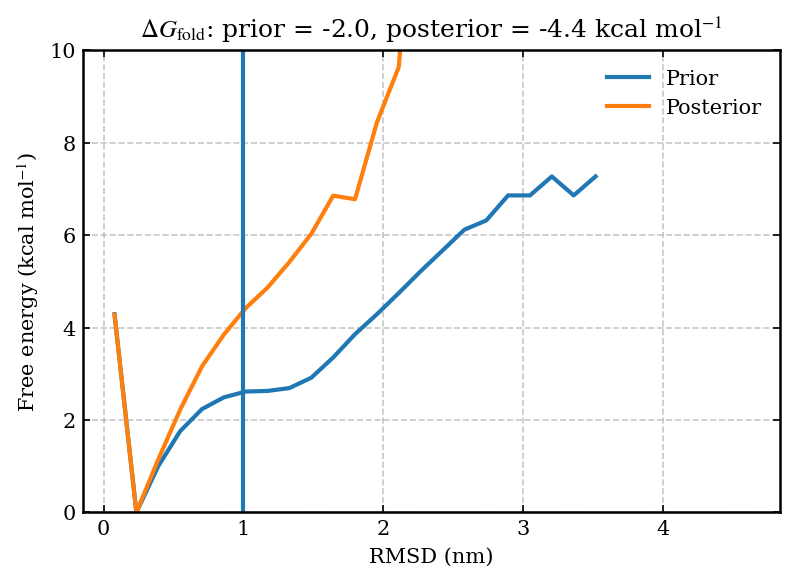

In [8]:
# free energy landscape of folding as a function of rmsd


nbins = 30

k = 0.008314
T = 298.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
folded_cutoff = 1.0

# load rmsd and frames data
for traj in trajs:
    if traj == trajs[0]:
        rmsd = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        rmsd = rmsd[okframes]
    else:
        tmprmsd = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        rmsd = np.concatenate((rmsd, tmprmsd[okframes]), axis=0)

w_prior = np.ones(len(rmsd))/len(rmsd)
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate folding free energies
folded = np.where(rmsd < folded_cutoff)[0]
unfolded = np.where(rmsd > folded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(rmsd, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(rmsd, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(rmsd, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')
plt.ylim(0,10)
plt.axvline(1.)

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('RMSD (nm)')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

In [9]:
len(rmsd)

284715

/tmp/ipykernel_354903/533915280.py:81: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


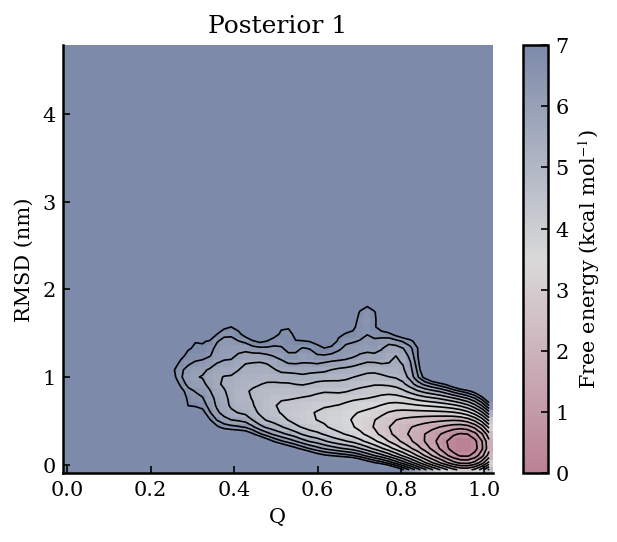

In [10]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 7.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 298.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_post1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_354903/3777980724.py:82: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


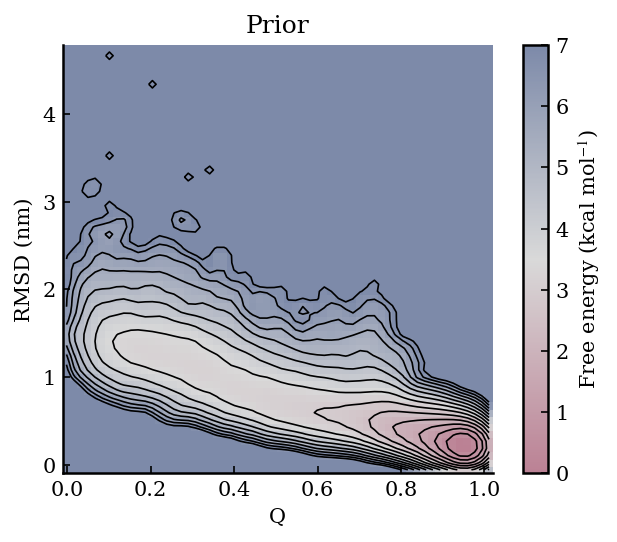

In [11]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 7.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# prior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
wopt = np.ones(len(wopt))/len(wopt)

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize prior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 298.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_354903/2702625064.py:114: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


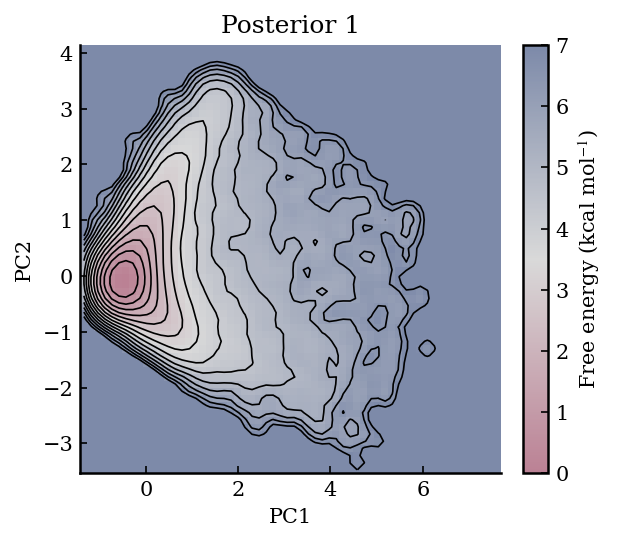

In [15]:
# PCA FEL
# FEL of posterior 1 (elbow) as a function of PC1 and PC2
# PCA coordinates contain all frames, so first sub-index using okframes
# from each trajectory in exactly the same sorted trajectory order

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 7.0
sigma = 1.0

# load PCA coordinates for all frames
pca = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# get trajectories in exactly the same order used for PCA/reweighting
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load trajectory frame ranges written by PCA script
frame_info = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/trajectory_frames.txt', dtype=str)

# build global indices corresponding to okframes from each trajectory
global_okframes = []

for i, traj in enumerate(trajs):
    traj_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert traj_name == traj, f"Trajectory order mismatch: PCA has {traj_name}, current order has {traj}"

    okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    global_okframes.append(start + okframes)

global_okframes = np.concatenate(global_okframes)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
pc1_use = np.asarray(pc1, dtype=float)
pc2_use = np.asarray(pc2, dtype=float)

if synframes > 0:
    pc1_use = pc1_use[:-synframes]
    pc2_use = pc2_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(pc1_use) == len(pc2_use) == len(wopt), f"PC1, PC2, and wopt must have the same length: {len(pc1_use)}, {len(pc2_use)}, {len(wopt)}"

# normalize weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(pc1_use), np.max(pc1_use)
ymin, ymax = np.min(pc2_use), np.max(pc2_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(pc1_use, pc2_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 298.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plot
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_PC1_PC2_FEL_posterior1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_387681/3833199420.py:115: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


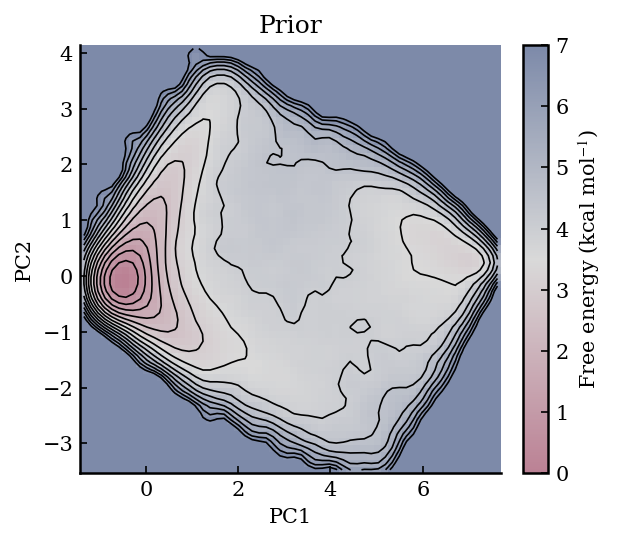

In [4]:
# PCA FEL
# FEL of prior as a function of PC1 and PC2
# PCA coordinates contain all frames, so first sub-index using okframes
# from each trajectory in exactly the same sorted trajectory order

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 7.0
sigma = 1.0

# load PCA coordinates for all frames
pca = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# get trajectories in exactly the same order used for PCA/reweighting
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load trajectory frame ranges written by PCA script
frame_info = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/trajectory_frames.txt', dtype=str)

# build global indices corresponding to okframes from each trajectory
global_okframes = []

for i, traj in enumerate(trajs):
    traj_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert traj_name == traj, f"Trajectory order mismatch: PCA has {traj_name}, current order has {traj}"

    okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    global_okframes.append(start + okframes)

global_okframes = np.concatenate(global_okframes)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# prior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
wopt = np.ones(wopt.shape[0])/wopt.shape[0]

# optional: drop synthetic frames at the end if present
pc1_use = np.asarray(pc1, dtype=float)
pc2_use = np.asarray(pc2, dtype=float)

if synframes > 0:
    pc1_use = pc1_use[:-synframes]
    pc2_use = pc2_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(pc1_use) == len(pc2_use) == len(wopt), f"PC1, PC2, and wopt must have the same length: {len(pc1_use)}, {len(pc2_use)}, {len(wopt)}"

# normalize weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(pc1_use), np.max(pc1_use)
ymin, ymax = np.min(pc2_use), np.max(pc2_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(pc1_use, pc2_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 298.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plot
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_PC1_PC2_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_354903/3878937841.py:126: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


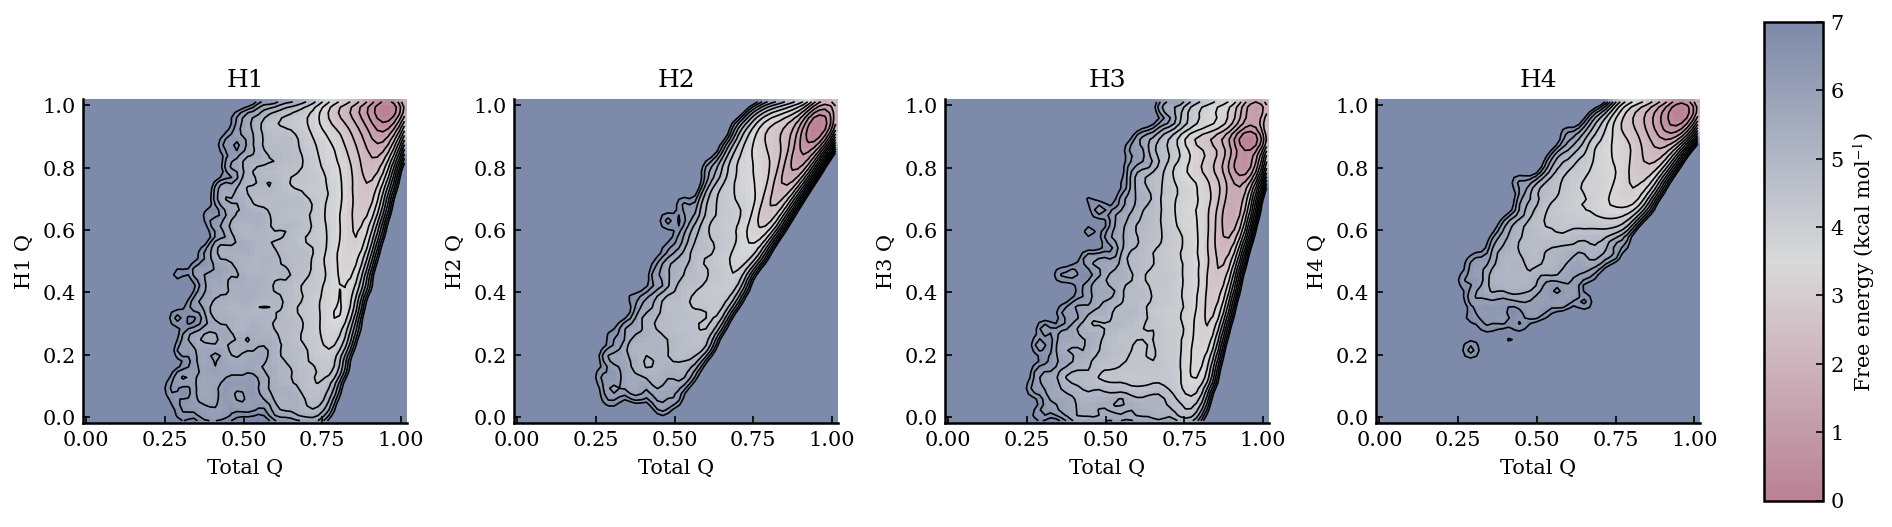

In [48]:
# FEL of posterior 1 (elbow) as a function of total Q
# and Q of helices h1-h4, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'BIOEMU_DATA'

protein = proteins[0]
helices = ['h1', 'h2', 'h3', 'h4']
synframes = 0
nbins = 60
max_energy = 7.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q{idx}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q{idx}.txt')

    okframes = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    okframes = np.atleast_1d(okframes)

    Q_total.append(np.asarray(tmp_Q_total).ravel()[okframes])

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel()[okframes])

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir2}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 283.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_post)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_posterior1_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()

/tmp/ipykernel_354903/3300869073.py:126: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


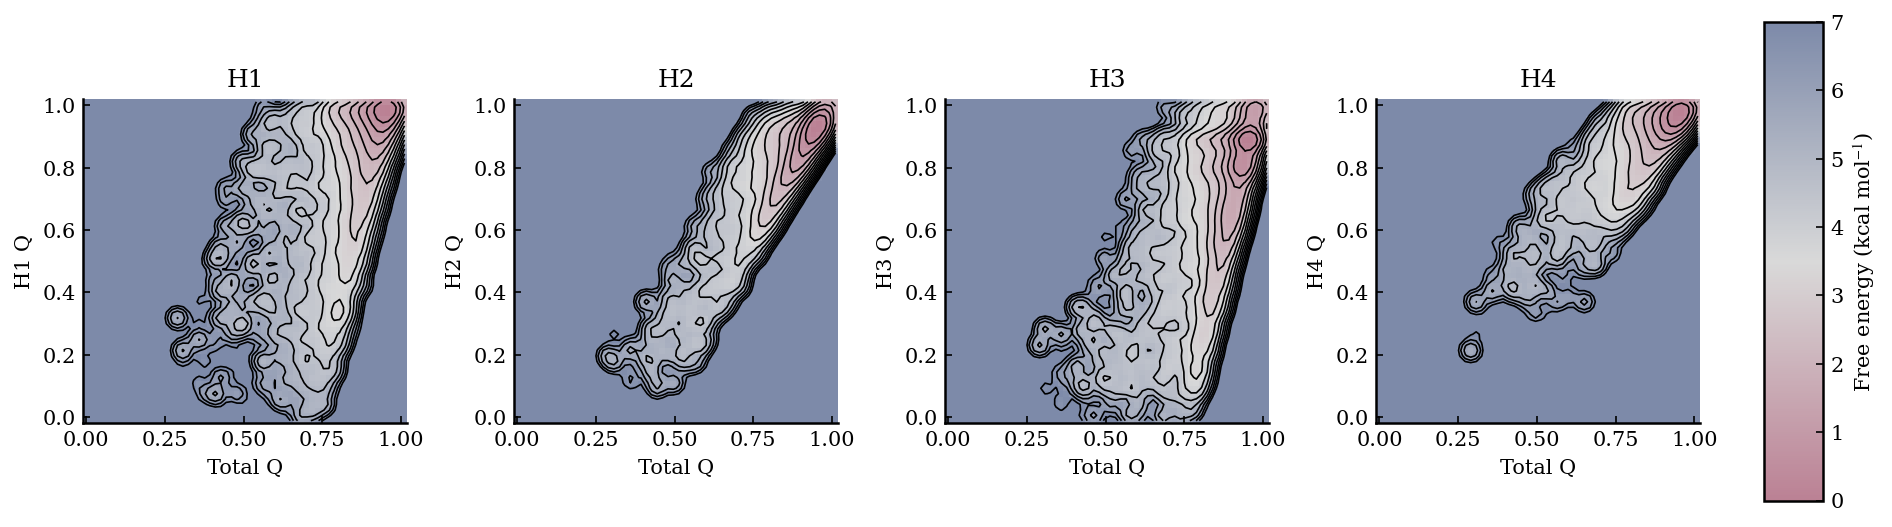

In [34]:
# FEL of posterior 1 (elbow) as a function of total Q
# and Q of helices h1-h4, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'BIOEMU_DATA'

protein = proteins[0]
helices = ['h1', 'h2', 'h3', 'h4']
synframes = 0
nbins = 60
max_energy = 7.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q{idx}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q{idx}.txt')

    okframes = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    okframes = np.atleast_1d(okframes)

    Q_total.append(np.asarray(tmp_Q_total).ravel()[okframes])

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel()[okframes])

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir2}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 283.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_post)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_posterior2_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()

/tmp/ipykernel_354903/2461961416.py:126: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


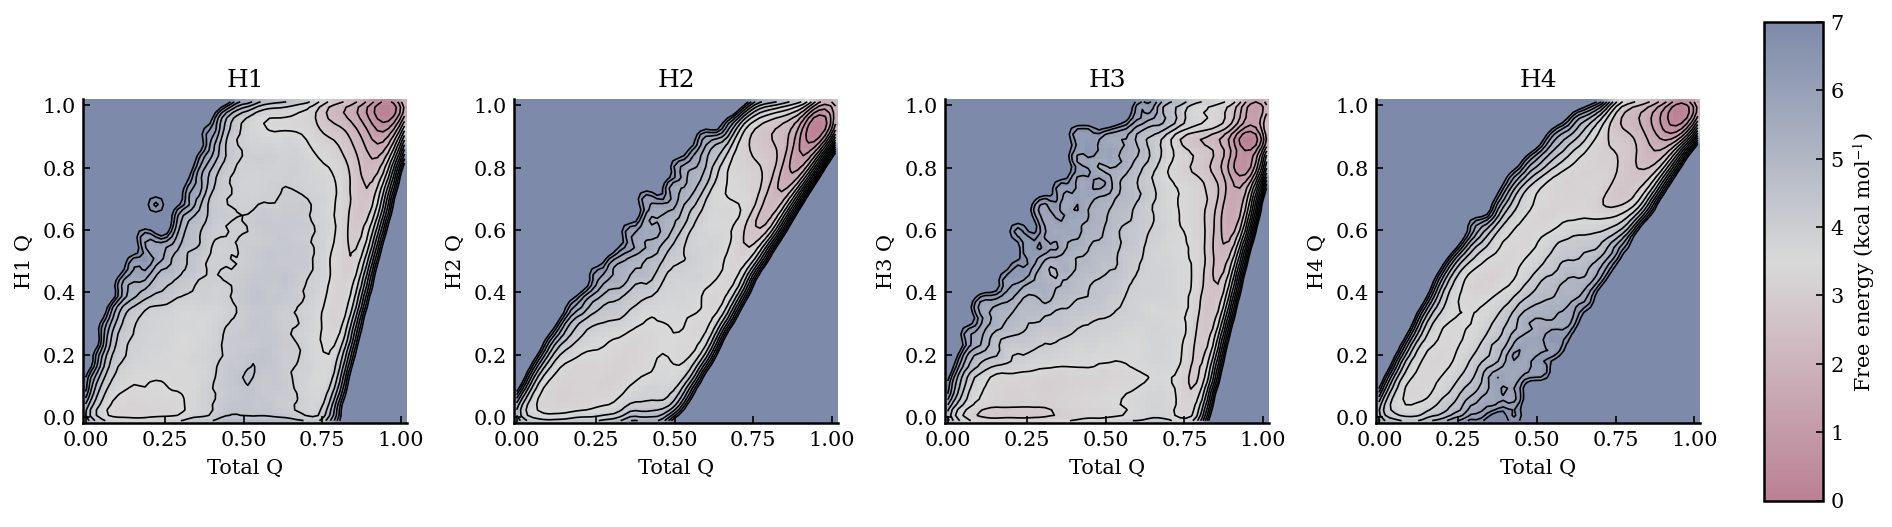

In [35]:
# FEL of prior as a function of total Q
# and Q of helices h1-h4, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'BIOEMU_DATA'

protein = proteins[0]
helices = ['h1', 'h2', 'h3', 'h4']
synframes = 0
nbins = 60
max_energy = 7.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q{idx}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q{idx}.txt')

    okframes = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    okframes = np.atleast_1d(okframes)

    Q_total.append(np.asarray(tmp_Q_total).ravel()[okframes])

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel()[okframes])

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# prior weights
wopt = np.ones(Q_total.shape[0])/Q_total.shape[0]

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize prior weights
w_prior = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 283.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_prior)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_prior_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()

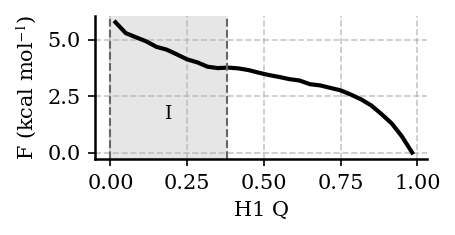

In [84]:
# plot 1D FEL of H1 Q
# only for the sub-ensemble with total Q > 0.7

nbins = 30

ensemble_master_dir = 'BIOEMU_DATA'

k = 0.008314
T = 298.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load total Q and H3 Q using the same okframes
for i, traj in enumerate(trajs):

    tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
    tmpQ_h1 = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts_h1/Q{traj[4:-4]}.txt')

    okframes = np.loadtxt(
        f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt'
    ).astype(int)

    okframes = np.atleast_1d(okframes)

    if traj == trajs[0]:
        Q = np.asarray(tmpQ).ravel()[okframes]
        Q_h1 = np.asarray(tmpQ_h1).ravel()[okframes]
    else:
        Q = np.concatenate((Q, np.asarray(tmpQ).ravel()[okframes]), axis=0)
        Q_h1 = np.concatenate((Q_h1, np.asarray(tmpQ_h1).ravel()[okframes]), axis=0)

# posterior weights
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# sanity check
assert len(Q) == len(Q_h1) == len(w_post), \
    f"Q, H1 Q, and weights must have the same length: {len(Q)}, {len(Q_h1)}, {len(w_post)}"

# restrict to sub-ensemble with total Q > 0.7
mask = Q > 0.7

Q_h1_sub = Q_h1[mask]
w_post_sub = w_post[mask]

# renormalize posterior weights within this sub-ensemble
w_post_sub = w_post_sub / np.sum(w_post_sub)

# calculate posterior FEL along H1 Q
bin_edges = np.histogram_bin_edges(Q_h1_sub, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(
    Q_h1_sub,
    bins=bin_edges,
    weights=w_post_sub
)

p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0

fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

ax.set_xlabel("H1 Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

U_cutoff = 0.0
I_cutoff = 0.38
# intermediate-state region: 0.0 < Q < 0.38
ax.axvspan(U_cutoff, I_cutoff, color="0.9", zorder=0)
ax.axvline(U_cutoff, color="0.4", ls="--", lw=1)
ax.axvline(I_cutoff, color="0.4", ls="--", lw=1)

ax.text(
    (U_cutoff + I_cutoff) / 2,
    ax.get_ylim()[1] * 0.35,
    "I",
    ha="center",
    va="top",
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()

plt.savefig(
    outdir+f'posterior1_fel_1D_H1Q_totalQ_gt_0.7.pdf',
    bbox_inches="tight"
)

plt.show()

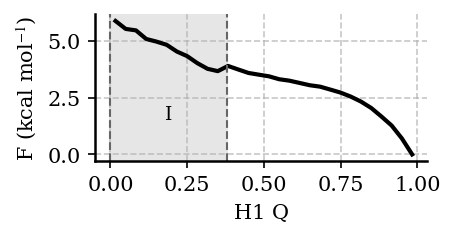

In [82]:
# plot 1D FEL of H1 Q posterior 2
# only for the sub-ensemble with total Q > 0.7

nbins = 30

ensemble_master_dir = 'BIOEMU_DATA'

k = 0.008314
T = 298.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load total Q and H3 Q using the same okframes
for i, traj in enumerate(trajs):

    tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
    tmpQ_h1 = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts_h1/Q{traj[4:-4]}.txt')

    okframes = np.loadtxt(
        f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt'
    ).astype(int)

    okframes = np.atleast_1d(okframes)

    if traj == trajs[0]:
        Q = np.asarray(tmpQ).ravel()[okframes]
        Q_h1 = np.asarray(tmpQ_h1).ravel()[okframes]
    else:
        Q = np.concatenate((Q, np.asarray(tmpQ).ravel()[okframes]), axis=0)
        Q_h1 = np.concatenate((Q_h1, np.asarray(tmpQ_h1).ravel()[okframes]), axis=0)

# posterior weights
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# sanity check
assert len(Q) == len(Q_h1) == len(w_post), \
    f"Q, H1 Q, and weights must have the same length: {len(Q)}, {len(Q_h1)}, {len(w_post)}"

# restrict to sub-ensemble with total Q > 0.7
mask = Q > 0.7

Q_h1_sub = Q_h1[mask]
w_post_sub = w_post[mask]

# renormalize posterior weights within this sub-ensemble
w_post_sub = w_post_sub / np.sum(w_post_sub)

# calculate posterior FEL along H1 Q
bin_edges = np.histogram_bin_edges(Q_h1_sub, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(
    Q_h1_sub,
    bins=bin_edges,
    weights=w_post_sub
)

p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0

fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

ax.set_xlabel("H1 Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

U_cutoff = 0.0
I_cutoff = 0.38
# intermediate-state region: 0.3 < Q < 0.4
ax.axvspan(U_cutoff, I_cutoff, color="0.9", zorder=0)
ax.axvline(U_cutoff, color="0.4", ls="--", lw=1)
ax.axvline(I_cutoff, color="0.4", ls="--", lw=1)

ax.text(
    (U_cutoff + I_cutoff) / 2,
    ax.get_ylim()[1] * 0.35,
    "I",
    ha="center",
    va="top",
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()

plt.savefig(
    outdir+f'posterior2_fel_1D_H1Q_totalQ_gt_0.7.pdf',
    bbox_inches="tight"
)

plt.show()

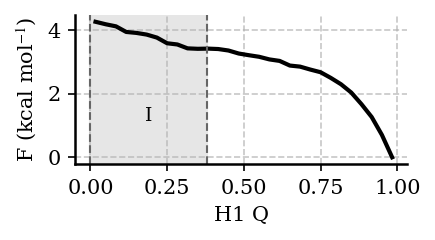

In [83]:
# plot 1D FEL of H1 Q prior
# only for the sub-ensemble with total Q > 0.7

nbins = 30

ensemble_master_dir = 'BIOEMU_DATA'

k = 0.008314
T = 298.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load total Q and H3 Q using the same okframes
for i, traj in enumerate(trajs):

    tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
    tmpQ_h1 = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts_h1/Q{traj[4:-4]}.txt')

    okframes = np.loadtxt(
        f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt'
    ).astype(int)

    okframes = np.atleast_1d(okframes)

    if traj == trajs[0]:
        Q = np.asarray(tmpQ).ravel()[okframes]
        Q_h1 = np.asarray(tmpQ_h1).ravel()[okframes]
    else:
        Q = np.concatenate((Q, np.asarray(tmpQ).ravel()[okframes]), axis=0)
        Q_h1 = np.concatenate((Q_h1, np.asarray(tmpQ_h1).ravel()[okframes]), axis=0)

# prior weights
w_post = np.ones(Q_h1.shape[0])/Q_h1.shape[0]

# sanity check
assert len(Q) == len(Q_h1) == len(w_post), \
    f"Q, H1 Q, and weights must have the same length: {len(Q)}, {len(Q_h1)}, {len(w_post)}"

# restrict to sub-ensemble with total Q > 0.7
mask = Q > 0.7

Q_h1_sub = Q_h1[mask]
w_post_sub = w_post[mask]

# renormalize posterior weights within this sub-ensemble
w_post_sub = w_post_sub / np.sum(w_post_sub)

# calculate posterior FEL along H1 Q
bin_edges = np.histogram_bin_edges(Q_h1_sub, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(
    Q_h1_sub,
    bins=bin_edges,
    weights=w_post_sub
)

p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0

fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

ax.set_xlabel("H1 Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

U_cutoff = 0.0
I_cutoff = 0.38
# intermediate-state region: 0.0 < Q < 0.38
ax.axvspan(U_cutoff, I_cutoff, color="0.9", zorder=0)
ax.axvline(U_cutoff, color="0.4", ls="--", lw=1)
ax.axvline(I_cutoff, color="0.4", ls="--", lw=1)

ax.text(
    (U_cutoff + I_cutoff) / 2,
    ax.get_ylim()[1] * 0.35,
    "I",
    ha="center",
    va="top",
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()

plt.savefig(
    outdir+f'prior_fel_1D_H1Q_totalQ_gt_0.7.pdf',
    bbox_inches="tight"
)

plt.show()

In [87]:
# save top 10 conformers closest to the 2D FEL minimum in the state (posterior 1)
# total Q > 0.7 and  0.0 < Q_H1 < 0.38
# ties / similarly close structures are ranked by posterior weight

import mdtraj as md
from pathlib import Path
from scipy.ndimage import gaussian_filter

q_total_cutoff = 0.7
q_h1_cutoff_1 = 0.0
q_h1_cutoff_2 = 0.38
n_conformers = 10

nbins = 60
sigma = 1.0

base_dir = Path(f'../../{ensemble_master_dir}/{protein}')
out_dir = Path(outdir+'intermediate_top10')
out_dir.mkdir(exist_ok=True)

trajs = sorted(find_xtc_filenames(base_dir))

Q_all = []
Q_h1_all = []
traj_all = []
frame_all = []

for i, traj in enumerate(trajs):

    Q = np.loadtxt(
        base_dir / f'native_contacts/Q{traj[4:-4]}.txt'
    )

    Q_h1 = np.loadtxt(
        base_dir / f'native_contacts_h1/Q{traj[4:-4]}.txt'
    )

    okframes = np.loadtxt(
        base_dir / f'rewM13DH_scaled/okframes_{traj[:-4]}.txt'
    ).astype(int)

    okframes = np.atleast_1d(okframes)

    Q_all.append(np.asarray(Q).ravel()[okframes])
    Q_h1_all.append(np.asarray(Q_h1).ravel()[okframes])

    traj_all.extend([traj] * len(okframes))
    frame_all.extend(okframes)

Q_all = np.concatenate(Q_all)
Q_h1_all = np.concatenate(Q_h1_all)

traj_all = np.array(traj_all)
frame_all = np.array(frame_all)

# posterior weights
w_post = np.load(
    f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy'
)

# sanity check
assert len(Q_all) == len(Q_h1_all) == len(w_post), \
    f"Q, H1 Q, and weights must have the same length: {len(Q_all)}, {len(Q_h1_all)}, {len(w_post)}"

# normalize weights
w_post = w_post / np.sum(w_post)

# ------------------------------------------------------------
# Reconstruct the same 2D posterior FEL: total Q vs H3 Q
# ------------------------------------------------------------

xmin, xmax = np.min(Q_all), np.max(Q_all)
ymin, ymax = np.min(Q_h1_all), np.max(Q_h1_all)

xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)

xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

H_post, xedges, yedges = np.histogram2d(
    Q_all,
    Q_h1_all,
    bins=[xbins, ybins],
    weights=w_post
)

# same Gaussian smoothing as FEL plot
H_post_smooth = gaussian_filter(
    H_post,
    sigma=sigma,
    mode='constant',
    cval=0.0
)

H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert to FEL
kB = 0.0019872041
T = 298.0

F_post = np.full_like(H_post_smooth, np.nan, dtype=float)

valid = H_post_smooth > 0

F_post[valid] = -kB * T * np.log(H_post_smooth[valid])
F_post -= np.nanmin(F_post)

# bin centers
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])

Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# ------------------------------------------------------------
# Find FEL minimum within:
# total Q > 0.8 and H1 Q between 0.0 and 0.38
# ------------------------------------------------------------

state_bins = (
    (Xc > q_total_cutoff) &
    (Yc > 0.0) &
    (Yc < 0.38) &
    np.isfinite(F_post)
)

if not np.any(state_bins):
    raise ValueError('No FEL bins satisfy the requested state definition.')

F_state = np.where(state_bins, F_post, np.nan)

min_idx = np.unravel_index(
    np.nanargmin(F_state),
    F_state.shape
)

Q_min = Xc[min_idx]
Q_h1_min = Yc[min_idx]
F_min = F_post[min_idx]

print('Intermediate-state FEL minimum:')
print(f'Total Q = {Q_min:.4f}')
print(f'H1 Q    = {Q_h1_min:.4f}')
print(f'F       = {F_min:.3f} kcal mol^-1')
print()

# ------------------------------------------------------------
# Select actual frames belonging to the state
# ------------------------------------------------------------

state = np.where(
    (Q_all > q_total_cutoff) &
    (Q_h1_all > 0.0) &
    (Q_h1_all < 0.38)
)[0]

print(f'State definition: total Q > {q_total_cutoff} and H1 Q {q_h1_cutoff_1}-{q_h1_cutoff_2}')
print(f'State frames: {len(state)}')
print(f'Posterior population: {np.sum(w_post[state]):.4f}')
print()

if len(state) == 0:
    raise ValueError('No frames satisfy the requested state definition.')

# ------------------------------------------------------------
# Distance of each frame from the 2D FEL minimum
# ------------------------------------------------------------

distance_to_min = np.sqrt(
    (Q_all[state] - Q_min)**2 +
    (Q_h1_all[state] - Q_h1_min)**2
)

# sort primarily by distance from FEL minimum
# and secondarily by highest posterior weight
order = np.lexsort(
    (-w_post[state], distance_to_min)
)

top = state[order[:n_conformers]]

# ------------------------------------------------------------
# Save conformers
# ------------------------------------------------------------

for rank, idx in enumerate(top, 1):

    traj_name = traj_all[idx]
    frame = frame_all[idx]

    distance = np.sqrt(
        (Q_all[idx] - Q_min)**2 +
        (Q_h1_all[idx] - Q_h1_min)**2
    )

    structure = md.load_frame(
        str(base_dir / traj_name),
        int(frame),
        top=str(base_dir / 'protein.pdb')
    )

    outfile = out_dir / (
        f'intermediate_{rank:02d}_'
        f'Q{Q_all[idx]:.4f}_'
        f'H1Q{Q_h1_all[idx]:.4f}_'
        f'd{distance:.4f}_'
        f'w{w_post[idx]:.6g}.pdb'
    )

    structure.save_pdb(str(outfile))

    print(
        f'{rank:2d}: {traj_name}, frame {frame:6d}, '
        f'Q = {Q_all[idx]:.4f}, '
        f'H1 Q = {Q_h1_all[idx]:.4f}, '
        f'distance = {distance:.4f}, '
        f'weight = {w_post[idx]:.6g}'
    )

Intermediate-state FEL minimum:
Total Q = 0.8052
H1 Q    = 0.3527
F       = 3.641 kcal mol^-1

State definition: total Q > 0.7 and H1 Q 0.0-0.38
State frames: 3325
Posterior population: 0.0052

 1: traj4.xtc, frame   8074, Q = 0.8050, H1 Q = 0.3516, distance = 0.0010, weight = 1.0133e-06
 2: traj12.xtc, frame   5699, Q = 0.8032, H1 Q = 0.3532, distance = 0.0020, weight = 4.06134e-06
 3: traj29.xtc, frame   9065, Q = 0.8053, H1 Q = 0.3549, distance = 0.0022, weight = 4.06542e-06
 4: traj28.xtc, frame   8680, Q = 0.8058, H1 Q = 0.3550, distance = 0.0024, weight = 3.33369e-06
 5: traj29.xtc, frame   8489, Q = 0.8028, H1 Q = 0.3536, distance = 0.0025, weight = 4.06194e-06
 6: traj21.xtc, frame   7159, Q = 0.8021, H1 Q = 0.3537, distance = 0.0032, weight = 2.30744e-06
 7: traj5.xtc, frame   5299, Q = 0.8050, H1 Q = 0.3492, distance = 0.0034, weight = 4.06509e-06
 8: traj18.xtc, frame   9403, Q = 0.8082, H1 Q = 0.3509, distance = 0.0035, weight = 3.94966e-09
 9: traj0.xtc, frame   6518, Q = 

In [88]:
# save top 10 conformers closest to the 2D FEL minimum in the state (posterior 2 since the minimum is clearer and phi still quite high ~0.55):
# total Q > 0.7 and  0.0 < Q_H1 < 0.38
# ties / similarly close structures are ranked by posterior weight

import mdtraj as md
from pathlib import Path
from scipy.ndimage import gaussian_filter

q_total_cutoff = 0.7
q_h1_cutoff_1 = 0.0
q_h1_cutoff_2 = 0.38
n_conformers = 10

nbins = 60
sigma = 1.0

base_dir = Path(f'../../{ensemble_master_dir}/{protein}')
out_dir = Path(outdir+'intermediate_top10_post2')
out_dir.mkdir(exist_ok=True)

trajs = sorted(find_xtc_filenames(base_dir))

Q_all = []
Q_h1_all = []
traj_all = []
frame_all = []

for i, traj in enumerate(trajs):

    Q = np.loadtxt(
        base_dir / f'native_contacts/Q{traj[4:-4]}.txt'
    )

    Q_h1 = np.loadtxt(
        base_dir / f'native_contacts_h1/Q{traj[4:-4]}.txt'
    )

    okframes = np.loadtxt(
        base_dir / f'rewM13DH_scaled/okframes_{traj[:-4]}.txt'
    ).astype(int)

    okframes = np.atleast_1d(okframes)

    Q_all.append(np.asarray(Q).ravel()[okframes])
    Q_h1_all.append(np.asarray(Q_h1).ravel()[okframes])

    traj_all.extend([traj] * len(okframes))
    frame_all.extend(okframes)

Q_all = np.concatenate(Q_all)
Q_h1_all = np.concatenate(Q_h1_all)

traj_all = np.array(traj_all)
frame_all = np.array(frame_all)

# posterior weights
w_post = np.load(
    f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy'
)

# sanity check
assert len(Q_all) == len(Q_h1_all) == len(w_post), \
    f"Q, H1 Q, and weights must have the same length: {len(Q_all)}, {len(Q_h1_all)}, {len(w_post)}"

# normalize weights
w_post = w_post / np.sum(w_post)

# ------------------------------------------------------------
# Reconstruct the same 2D posterior FEL: total Q vs H1 Q
# ------------------------------------------------------------

xmin, xmax = np.min(Q_all), np.max(Q_all)
ymin, ymax = np.min(Q_h1_all), np.max(Q_h1_all)

xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)

xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

H_post, xedges, yedges = np.histogram2d(
    Q_all,
    Q_h1_all,
    bins=[xbins, ybins],
    weights=w_post
)

# same Gaussian smoothing as FEL plot
H_post_smooth = gaussian_filter(
    H_post,
    sigma=sigma,
    mode='constant',
    cval=0.0
)

H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert to FEL
kB = 0.0019872041
T = 298.0

F_post = np.full_like(H_post_smooth, np.nan, dtype=float)

valid = H_post_smooth > 0

F_post[valid] = -kB * T * np.log(H_post_smooth[valid])
F_post -= np.nanmin(F_post)

# bin centers
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])

Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# ------------------------------------------------------------
# Find FEL minimum within:
# total Q > 0.8 and H1 Q between 0.0 and 0.38
# ------------------------------------------------------------

state_bins = (
    (Xc > q_total_cutoff) &
    (Yc > 0.0) &
    (Yc < 0.38) &
    np.isfinite(F_post)
)

if not np.any(state_bins):
    raise ValueError('No FEL bins satisfy the requested state definition.')

F_state = np.where(state_bins, F_post, np.nan)

min_idx = np.unravel_index(
    np.nanargmin(F_state),
    F_state.shape
)

Q_min = Xc[min_idx]
Q_h1_min = Yc[min_idx]
F_min = F_post[min_idx]

print('Intermediate-state FEL minimum:')
print(f'Total Q = {Q_min:.4f}')
print(f'H1 Q    = {Q_h1_min:.4f}')
print(f'F       = {F_min:.3f} kcal mol^-1')
print()

# ------------------------------------------------------------
# Select actual frames belonging to the state
# ------------------------------------------------------------

state = np.where(
    (Q_all > q_total_cutoff) &
    (Q_h1_all > 0.0) &
    (Q_h1_all < 0.38)
)[0]

print(f'State definition: total Q > {q_total_cutoff} and H1 Q {q_h1_cutoff_1}-{q_h1_cutoff_2}')
print(f'State frames: {len(state)}')
print(f'Posterior population: {np.sum(w_post[state]):.4f}')
print()

if len(state) == 0:
    raise ValueError('No frames satisfy the requested state definition.')

# ------------------------------------------------------------
# Distance of each frame from the 2D FEL minimum
# ------------------------------------------------------------

distance_to_min = np.sqrt(
    (Q_all[state] - Q_min)**2 +
    (Q_h1_all[state] - Q_h1_min)**2
)

# sort primarily by distance from FEL minimum
# and secondarily by highest posterior weight
order = np.lexsort(
    (-w_post[state], distance_to_min)
)

top = state[order[:n_conformers]]

# ------------------------------------------------------------
# Save conformers
# ------------------------------------------------------------

for rank, idx in enumerate(top, 1):

    traj_name = traj_all[idx]
    frame = frame_all[idx]

    distance = np.sqrt(
        (Q_all[idx] - Q_min)**2 +
        (Q_h1_all[idx] - Q_h1_min)**2
    )

    structure = md.load_frame(
        str(base_dir / traj_name),
        int(frame),
        top=str(base_dir / 'protein.pdb')
    )

    outfile = out_dir / (
        f'intermediate_{rank:02d}_'
        f'Q{Q_all[idx]:.4f}_'
        f'H1Q{Q_h1_all[idx]:.4f}_'
        f'd{distance:.4f}_'
        f'w{w_post[idx]:.6g}.pdb'
    )

    structure.save_pdb(str(outfile))

    print(
        f'{rank:2d}: {traj_name}, frame {frame:6d}, '
        f'Q = {Q_all[idx]:.4f}, '
        f'H1 Q = {Q_h1_all[idx]:.4f}, '
        f'distance = {distance:.4f}, '
        f'weight = {w_post[idx]:.6g}'
    )

Intermediate-state FEL minimum:
Total Q = 0.8052
H1 Q    = 0.3353
F       = 3.535 kcal mol^-1

State definition: total Q > 0.7 and H1 Q 0.0-0.38
State frames: 3325
Posterior population: 0.0046

 1: traj27.xtc, frame   3487, Q = 0.8043, H1 Q = 0.3346, distance = 0.0011, weight = 2.37855e-08
 2: traj23.xtc, frame    722, Q = 0.8039, H1 Q = 0.3337, distance = 0.0020, weight = 1.96164e-06
 3: traj13.xtc, frame   5791, Q = 0.8053, H1 Q = 0.3379, distance = 0.0026, weight = 2.63057e-06
 4: traj5.xtc, frame   1309, Q = 0.8056, H1 Q = 0.3326, distance = 0.0027, weight = 1.0517e-09
 5: traj21.xtc, frame   6771, Q = 0.8055, H1 Q = 0.3382, distance = 0.0029, weight = 9.60535e-09
 6: traj5.xtc, frame   7121, Q = 0.8080, H1 Q = 0.3361, distance = 0.0029, weight = 2.93876e-08
 7: traj27.xtc, frame   7201, Q = 0.8033, H1 Q = 0.3330, distance = 0.0030, weight = 1.42637e-06
 8: traj13.xtc, frame   8630, Q = 0.8085, H1 Q = 0.3361, distance = 0.0035, weight = 3.30353e-07
 9: traj24.xtc, frame   5958, Q =

In [73]:
# secondary structure

import mdtraj as md

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# Function to calculate per-residue helicity per frame
def dssp_to_strand(dssp_lines):
    """
    same thing for beta strand
    """
    strand_codes = {'E', 'B'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    strandicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        strandicity[i, :] = [1 if c in strand_codes else 0 for c in line]
    
    return strandicity

# comparison with secondary structure / helicity
path = '../../BIOEMU_DATA/ACBP/'

traj_names = np.sort(find_xtc_filenames(path))

dssp_all = []

for traj in traj_names:
    u = md.load(
        path + f'./{traj}',
        top=path + f'./protein.pdb'
    )

    okframes = np.loadtxt(path+f'rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)

    heavyatoms = u.topology.select('not element H')
    u = u.atom_slice(heavyatoms)

    tmpdssp = md.compute_dssp(u)
    dssp_all.append(tmpdssp[okframes])

dssp = np.concatenate(dssp_all, axis=0)
np.save(path+'dssp_all_trajs_okframes.npy', dssp)



I frames: 3328
N frames: 261144
I posterior population: 0.0052
N posterior population: 0.9882


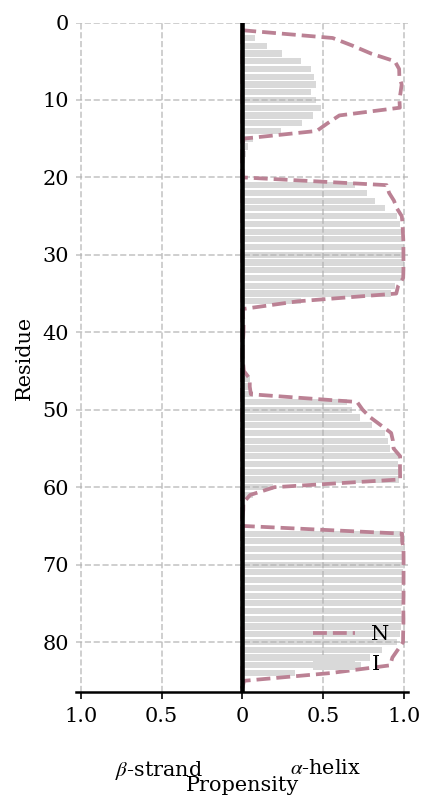

In [89]:
# secondary-structure propensity of the intermediate state relative to the native state
# beta to the left, alpha to the right
# I: Q > 0.7 and Q_h1 0.0-0.38
# N: Q > 0.7 and Q_h1 > 0.38

# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

ensemble_master_dir = 'BIOEMU_DATA'

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# sanity check
assert len(Q_all) == len(Q_h1_all) == len(wopt) == helicity.shape[0] == strand.shape[0], f"Frame counts do not match: Q={len(Q)}, Q_h1={len(Q_h1)}, wopt={len(wopt)}, DSSP={helicity.shape[0]}"

# state definitions
mask_I = (Q_all > 0.7) & (Q_h1_all < 0.38) 
mask_N = (Q_all > 0.7) & (Q_h1_all > 0.38)

print(f'I frames: {np.sum(mask_I)}')
print(f'N frames: {np.sum(mask_N)}')
print(f'I posterior population: {np.sum(wopt[mask_I]):.4f}')
print(f'N posterior population: {np.sum(wopt[mask_N]):.4f}')

# weighted propensities
alpha_I = np.average(helicity[mask_I], axis=0, weights=wopt[mask_I])
beta_I = np.average(strand[mask_I], axis=0, weights=wopt[mask_I])
alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# intermediate state as bars
ax.barh(residues, -beta_I, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_I, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'N_I_H1_states_SS.pdf', bbox_inches="tight")
plt.show()

I frames: 3328
N frames: 261144
I posterior population: 0.0046
N posterior population: 0.9904


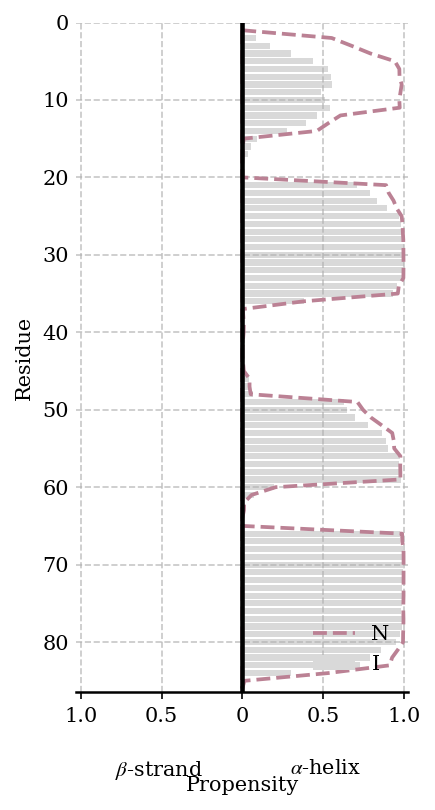

In [90]:
# secondary-structure propensity of the intermediate state relative to the native state posterior 2
# beta to the left, alpha to the right
# I: Q > 0.7 and Q_h1 0-0.38
# N: Q > 0.7 and Q_h1 > 0.38

# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

ensemble_master_dir = 'BIOEMU_DATA'

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# sanity check
assert len(Q_all) == len(Q_h1_all) == len(wopt) == helicity.shape[0] == strand.shape[0], f"Frame counts do not match: Q={len(Q)}, Q_h1={len(Q_h1)}, wopt={len(wopt)}, DSSP={helicity.shape[0]}"

# state definitions
mask_I = (Q_all > 0.7) & (Q_h1_all < 0.38) 
mask_N = (Q_all > 0.7) & (Q_h1_all > 0.38)

print(f'I frames: {np.sum(mask_I)}')
print(f'N frames: {np.sum(mask_N)}')
print(f'I posterior population: {np.sum(wopt[mask_I]):.4f}')
print(f'N posterior population: {np.sum(wopt[mask_N]):.4f}')

# weighted propensities
alpha_I = np.average(helicity[mask_I], axis=0, weights=wopt[mask_I])
beta_I = np.average(strand[mask_I], axis=0, weights=wopt[mask_I])
alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# intermediate state as bars
ax.barh(residues, -beta_I, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_I, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'N_I_H1_states_SS_post2.pdf', bbox_inches="tight")
plt.show()

I frames: 3328
N frames: 261144
I posterior population: 0.0117
N posterior population: 0.9172


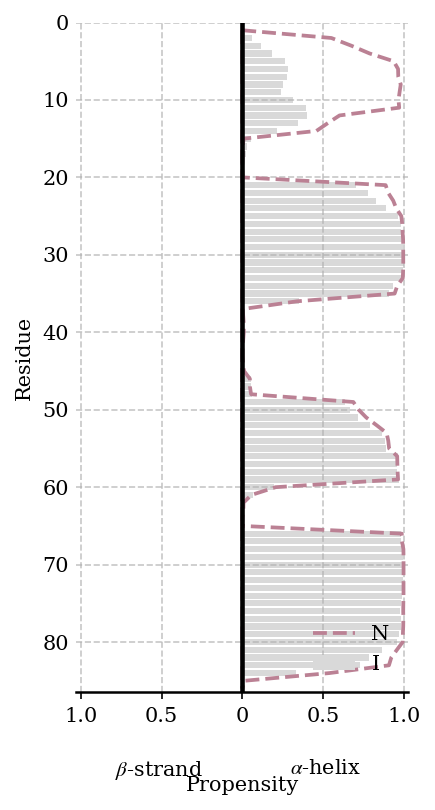

In [91]:
# secondary-structure propensity of the intermediate state relative to the native state - prior
# beta to the left, alpha to the right
# I: Q > 0.7 and Q_h1 0.0-0.38
# N: Q > 0.7 and Q_h1 > 0.38

# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

ensemble_master_dir = 'BIOEMU_DATA'

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# prior weights
wopt = np.ones(Q_all.shape[0])/Q_all.shape[0]

# sanity check
assert len(Q_all) == len(Q_h1_all) == len(wopt) == helicity.shape[0] == strand.shape[0], f"Frame counts do not match: Q={len(Q)}, Q_h1={len(Q_h1)}, wopt={len(wopt)}, DSSP={helicity.shape[0]}"

# state definitions
mask_I = (Q_all > 0.7) & (Q_h1_all < 0.38)
mask_N = (Q_all > 0.7) & (Q_h1_all > 0.38)

print(f'I frames: {np.sum(mask_I)}')
print(f'N frames: {np.sum(mask_N)}')
print(f'I posterior population: {np.sum(wopt[mask_I]):.4f}')
print(f'N posterior population: {np.sum(wopt[mask_N]):.4f}')

# weighted propensities
alpha_I = np.average(helicity[mask_I], axis=0, weights=wopt[mask_I])
beta_I = np.average(strand[mask_I], axis=0, weights=wopt[mask_I])
alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# intermediate state as bars
ax.barh(residues, -beta_I, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_I, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'N_I_H1_states_SS_prior.pdf', bbox_inches="tight")
plt.show()